
# 1. Random Forest

## 1.1 Objetivo

Implementar e avaliar o algoritmo Random Forest para classificação de clientes quanto à ocorrência de cancelamento dos serviços de telecomunicações (Churn).

Serão investigadas duas configurações de hiperparâmetros, utilizando validação cruzada estratificada com cinco partições previamente preparadas.

O desempenho será avaliado por meio das métricas de acurácia, precisão, revocação, F1-score e matriz de confusão.


In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

print("Biblioteca da Random Florest importada com sucesso.")


Biblioteca da Random Florest importada com sucesso.


In [ ]:
# Identificando diretório do projeto

current_dir = Path.cwd().resolve()

if current_dir.name.lower() == "notebooks":
    project_dir = current_dir.parent
else:
    project_dir = current_dir

# Localização do Dataset
fold_dir = project_dir / "data" / "processed" / "folds"

# Diretorio dos resultados
results_dir = project_dir / "reports" / "modelos"
results_dir.mkdir(parents=True, exist_ok=True)

print("Project:", project_dir)
print("Folds:", fold_dir)
print("Results:", results_dir)


Project: C:\Users\caior\OneDrive\Desktop\SegundoTrabalhoIN\Telco_Churn_Grupo1\telco-churn-grupo1
Folds: C:\Users\caior\OneDrive\Desktop\SegundoTrabalhoIN\Telco_Churn_Grupo1\telco-churn-grupo1\data\processed\folds
Results: C:\Users\caior\OneDrive\Desktop\SegundoTrabalhoIN\Telco_Churn_Grupo1\telco-churn-grupo1\reports\modelos


In [ ]:
# Definindo configurações das duas Random Forest que vão ser criadas

rf_configurations = {

    "RF_A_Baseline": { # A primeira não tem uma profundidade definida
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": "sqrt",
        "class_weight": None
    },

    "RF_B_Regularized": { # A segunda tem uma profundidade definida de 12 níveis
        "n_estimators": 300,
        "max_depth": 12,
        "min_samples_split": 2,
        "min_samples_leaf": 2,
        "max_features": "sqrt",
        "class_weight": None
    }

}

display(pd.DataFrame(rf_configurations).T)


,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
RF_A_Baseline,300,None,2,1,sqrt,None
RF_B_Regularized,300,12,2,2,sqrt,None


In [12]:
# Metricas coletadas para cada fold
rf_results = []

# Matrizes de confusão e predições
rf_confusion_matrices = {}
rf_oof_results = {}

# Recursos de importancia dos folds
rf_feature_importances = {}

metric_columns = [
    "Acurácia (accuracy)",
    "Precisão (precision)",
    "Revocação (recall)",
    "F1-score"
]

# Run each configuration
for configuration_name, parameters in rf_configurations.items():

    print("\n" + "=" * 65)
    print(f"RODANDO: {configuration_name}")
    print("=" * 65)

    total_confusion_matrix = np.zeros((2, 2), dtype=int)

    all_y_true = []
    all_y_pred = []

    fold_importances = []

    # Execute five-fold cross-validation
    for fold_number in range(1, 6):

        fold_path = fold_dir / f"fold_{fold_number}.npz"

        # Load the prepared fold
        with np.load(fold_path, allow_pickle=False) as fold:

            X_train = fold["X_train"]
            X_valid = fold["X_valid"]

            y_train = fold["y_train"]
            y_valid = fold["y_valid"]

            feature_names = fold["feature_names"].astype(str)

        # Initialize classifier
        model = RandomForestClassifier(
            **parameters,
            random_state=42,
            n_jobs=-1
        )

        # Train
        model.fit(X_train, y_train)

        # Predict
        y_pred = model.predict(X_valid)

        # Calculate metrics
        accuracy = accuracy_score(y_valid, y_pred)

        precision = precision_score(
            y_valid, y_pred,
            pos_label=1,
            zero_division=0
        )

        recall = recall_score(
            y_valid, y_pred,
            pos_label=1,
            zero_division=0
        )

        f1 = f1_score(
            y_valid, y_pred,
            pos_label=1,
            zero_division=0
        )

        # Calculate confusion matrix
        cm = confusion_matrix(
            y_valid,
            y_pred,
            labels=[0, 1]
        )

        # Accumulate results
        total_confusion_matrix += cm

        all_y_true.extend(y_valid.tolist())
        all_y_pred.extend(y_pred.tolist())

        fold_importances.append(
            pd.Series(
                model.feature_importances_,
                index=feature_names
            )
        )

        # Save individual fold results
        rf_results.append({
            "Configuração": configuration_name,
            "fold": fold_number,
            "Acurácia (accuracy)": accuracy,
            "Precisão (precision)": precision,
            "Revocação (recall)": recall,
            "F1-score": f1
        })

        print(
            f"Fold {fold_number}: "
            f"Acurácia (accuracy)={accuracy:.4f} | "
            f"Precisão (precision)={precision:.4f} | "
            f"Revocação (recall)={recall:.4f} | "
            f"F1-score={f1:.4f}"
        )

    # Save aggregated confusion matrix
    rf_confusion_matrices[configuration_name] = (
        total_confusion_matrix
    )

    # Save average feature importance
    rf_feature_importances[configuration_name] = (
        pd.concat(fold_importances, axis=1)
        .mean(axis=1)
        .sort_values(ascending=False)
    )

    # Calculate overall out-of-fold metrics
    oof_accuracy = accuracy_score(all_y_true, all_y_pred)

    oof_precision = precision_score(
        all_y_true,
        all_y_pred,
        pos_label=1,
        zero_division=0
    )

    oof_recall = recall_score(
        all_y_true,
        all_y_pred,
        pos_label=1,
        zero_division=0
    )

    oof_f1 = f1_score(
        all_y_true,
        all_y_pred,
        pos_label=1,
        zero_division=0
    )

    rf_oof_results[configuration_name] = {
        "accuracy": oof_accuracy,
        "precision": oof_precision,
        "recall": oof_recall,
        "f1_score": oof_f1
    }

print("\nTodos experimentos de Random Forest foram terminados!")



RODANDO: RF_A_Baseline
Fold 1: Acurácia (accuracy)=0.7892 | Precisão (precision)=0.6442 | Revocação (recall)=0.4599 | F1-score=0.5367
Fold 2: Acurácia (accuracy)=0.7999 | Precisão (precision)=0.6631 | Revocação (recall)=0.5000 | F1-score=0.5701
Fold 3: Acurácia (accuracy)=0.8048 | Precisão (precision)=0.6701 | Revocação (recall)=0.5214 | F1-score=0.5865
Fold 4: Acurácia (accuracy)=0.7884 | Precisão (precision)=0.6218 | Revocação (recall)=0.5187 | F1-score=0.5656
Fold 5: Acurácia (accuracy)=0.7997 | Precisão (precision)=0.6454 | Revocação (recall)=0.5416 | F1-score=0.5889

RODANDO: RF_B_Regularized
Fold 1: Acurácia (accuracy)=0.8041 | Precisão (precision)=0.6678 | Revocação (recall)=0.5214 | F1-score=0.5856
Fold 2: Acurácia (accuracy)=0.8084 | Precisão (precision)=0.6831 | Revocação (recall)=0.5187 | F1-score=0.5897
Fold 3: Acurácia (accuracy)=0.8204 | Precisão (precision)=0.6997 | Revocação (recall)=0.5668 | F1-score=0.6263
Fold 4: Acurácia (accuracy)=0.7990 | Precisão (precision)=0.6

In [21]:
# Tabelas dos resultados


rf_results_df = pd.DataFrame(rf_results)

display(
    rf_results_df.round(4)
)


# Média dos resultados por configuração
rf_summary = (
    rf_results_df
    .groupby("Configuração")[metric_columns]
    .agg(["mean", "std"])
)

# Simplify column names
rf_summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in rf_summary.columns
]

display(rf_summary.round(4))


rf_oof_df = pd.DataFrame(rf_oof_results).T

display(rf_oof_df.round(4))


,Configuração,fold,Acurácia (accuracy),Precisão (precision),Revocação (recall),F1-score
0,RF_A_Baseline,1,0.7892,0.6442,0.4599,0.5367
1,RF_A_Baseline,2,0.7999,0.6631,0.5000,0.5701
2,RF_A_Baseline,3,0.8048,0.6701,0.5214,0.5865
3,RF_A_Baseline,4,0.7884,0.6218,0.5187,0.5656
4,RF_A_Baseline,5,0.7997,0.6454,0.5416,0.5889
5,RF_B_Regularized,1,0.8041,0.6678,0.5214,0.5856
6,RF_B_Regularized,2,0.8084,0.6831,0.5187,0.5897
7,RF_B_Regularized,3,0.8204,0.6997,0.5668,0.6263
8,RF_B_Regularized,4,0.7990,0.6426,0.5481,0.5916
9,RF_B_Regularized,5,0.8146,0.6783,0.5710,0.6201


,Acurácia (accuracy)_mean,Acurácia (accuracy)_std,Precisão (precision)_mean,Precisão (precision)_std,Revocação (recall)_mean,Revocação (recall)_std,F1-score_mean,F1-score_std
Configuração,,,,,,,,
RF_A_Baseline,0.7964,0.0073,0.6489,0.0188,0.5083,0.0308,0.5696,0.021
RF_B_Regularized,0.8093,0.0085,0.6743,0.0211,0.5452,0.0246,0.6027,0.019


,accuracy,precision,recall,f1_score
RF_A_Baseline,0.7964,0.6485,0.5083,0.5699
RF_B_Regularized,0.8093,0.6739,0.5452,0.6028


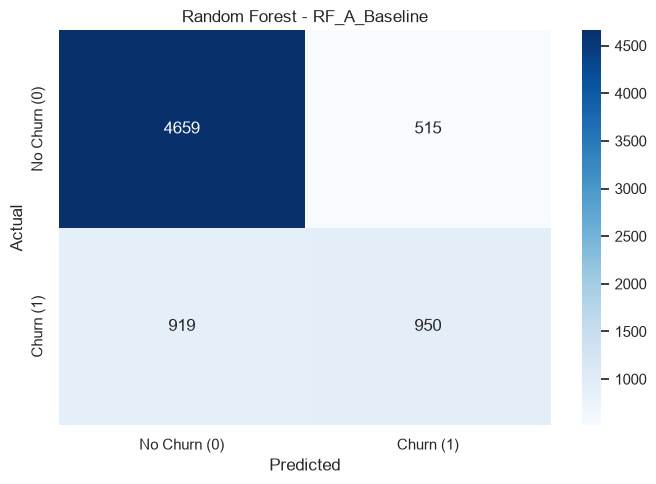

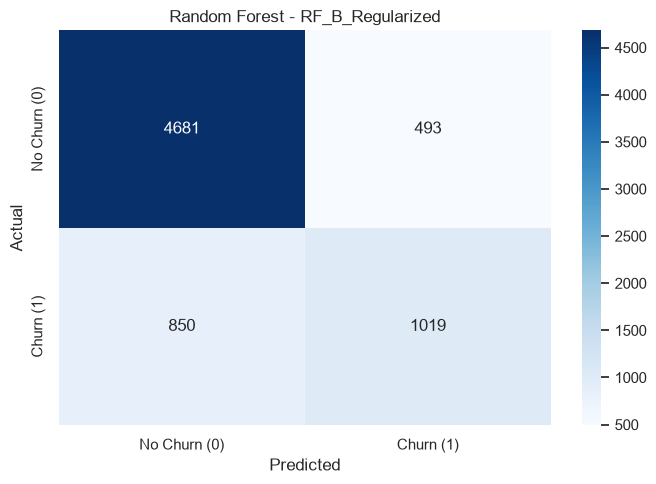

In [ ]:
# Matriz de confusão

for configuration_name, cm in rf_confusion_matrices.items():

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn (0)", "Churn (1)"],
        yticklabels=["No Churn (0)", "Churn (1)"]
    )

    plt.title(
        f"Random Forest - {configuration_name}"
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.show()


In [24]:
# Cria diretorio para matriz de confusão
confusion_dir = results_dir / "matrizes_confusao"
confusion_dir.mkdir(parents=True, exist_ok=True)

# Salva individualmente os resultados de fold
rf_results_df.to_csv(
    results_dir / "random_forest_resultados_por_fold.csv",
    index=False
)

# Salva o sumário
rf_summary.to_csv(
    results_dir / "random_forest_resumo.csv"
)

# Salva conjunto dos resultados de fold
rf_oof_df.to_csv(
    results_dir / "random_forest_resultados_oof.csv"
)

# Salva as matrizes de confusão
for configuration_name, cm in rf_confusion_matrices.items():

    cm_df = pd.DataFrame(
        cm,
        index=["Actual No Churn", "Actual Churn"],
        columns=["Predicted No Churn", "Predicted Churn"]
    )

    cm_df.to_csv(
        confusion_dir / f"{configuration_name}.csv"
    )


print("Resultados de Random Forest salvos!")


Resultados de Random Forest salvos!




# 2. XGBoost

## 2.1 Objetivo

Implementar e avaliar o algoritmo XGBoost para classificação de clientes quanto à ocorrência de cancelamento dos serviços de telecomunicações (Churn).

Serão investigadas duas configurações de hiperparâmetros, utilizando as mesmas cinco partições da validação cruzada estratificada aplicadas ao Random Forest.

O desempenho será avaliado por meio das métricas de acurácia, precisão, revocação, F1-score e matriz de confusão.


In [25]:
# Importa biblioteca de XGBoost e define configurações de parâmetros

from xgboost import XGBClassifier


xgb_configurations = {

    "XGB_A_Baseline": {
        "n_estimators": 200,
        "max_depth": 3,
        "learning_rate": 0.10,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1
    },

    "XGB_B_Regularized": {
        "n_estimators": 400,
        "max_depth": 3,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 2
    }

}

display(pd.DataFrame(xgb_configurations).T)


,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,reg_lambda
XGB_A_Baseline,200.0,3.0,0.10,0.8,0.8,1.0
XGB_B_Regularized,400.0,3.0,0.05,0.8,0.8,2.0


In [26]:

# Lista para guardar resultados
xgb_results = []

xgb_confusion_matrices = {}
xgb_oof_results = {}
xgb_feature_importances = {}

# Executa as duas configurações
for configuration_name, parameters in xgb_configurations.items():

    print("\n" + "=" * 65)
    print(f"RUNNING: {configuration_name}")
    print("=" * 65)

    total_confusion_matrix = np.zeros((2, 2), dtype=int)

    all_y_true = []
    all_y_pred = []

    fold_importances = []

    # Validação de cinco partições
    for fold_number in range(1, 6):

        fold_path = fold_dir / f"fold_{fold_number}.npz"

        # Carrega o fold
        with np.load(fold_path, allow_pickle=False) as fold:

            X_train = fold["X_train"]
            X_valid = fold["X_valid"]

            y_train = fold["y_train"]
            y_valid = fold["y_valid"]

            feature_names = fold["feature_names"].astype(str)

        # Cria um classificador
        model = XGBClassifier(
            **parameters,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )

        # Treina o modelo
        model.fit(X_train, y_train)

        # Prediz os resultados
        y_pred = model.predict(X_valid)

        # Calculo de métricas
        accuracy = accuracy_score(y_valid, y_pred)

        precision = precision_score(
            y_valid,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        recall = recall_score(
            y_valid,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        f1 = f1_score(
            y_valid,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        # Matriz de confusão
        cm = confusion_matrix(
            y_valid,
            y_pred,
            labels=[0, 1]
        )

        total_confusion_matrix += cm

        all_y_true.extend(y_valid.tolist())
        all_y_pred.extend(y_pred.tolist())

        # Feature importance
        fold_importances.append(
            pd.Series(
                model.feature_importances_,
                index=feature_names
            )
        )

        # Armazena os resultados
        xgb_results.append({
            "configuration": configuration_name,
            "fold": fold_number,
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1_score": f1
        })

        print(
            f"Fold {fold_number}: "
            f"Acurácia (accuracy)={accuracy:.4f} | "
            f"Precisão (precision)={precision:.4f} | "
            f"Revocação (recall)={recall:.4f} | "
            f"F1-score={f1:.4f}"
        )

    # Armazena matriz de confusão
    xgb_confusion_matrices[configuration_name] = (
        total_confusion_matrix
    )

    # Métricas de fold
    xgb_oof_results[configuration_name] = {
        "accuracy": accuracy_score(all_y_true, all_y_pred),

        "precision": precision_score(
            all_y_true, all_y_pred,
            pos_label=1,
            zero_division=0
        ),

        "recall": recall_score(
            all_y_true, all_y_pred,
            pos_label=1,
            zero_division=0
        ),

        "f1_score": f1_score(
            all_y_true, all_y_pred,
            pos_label=1,
            zero_division=0
        )
    }

print("\Todos experimentos de XGBoost realizados")


<>:144: SyntaxWarning: invalid escape sequence '\T'
<>:144: SyntaxWarning: invalid escape sequence '\T'
C:\Users\caior\AppData\Local\Temp\ipykernel_8736\2312059594.py:144: SyntaxWarning: invalid escape sequence '\T'
  print("\Todos experimentos de XGBoost realizados")



RUNNING: XGB_A_Baseline
Fold 1: Acurácia (accuracy)=0.7935 | Precisão (precision)=0.6293 | Revocação (recall)=0.5401 | F1-score=0.5813
Fold 2: Acurácia (accuracy)=0.8020 | Precisão (precision)=0.6610 | Revocação (recall)=0.5214 | F1-score=0.5830
Fold 3: Acurácia (accuracy)=0.8197 | Precisão (precision)=0.6923 | Revocação (recall)=0.5775 | F1-score=0.6297
Fold 4: Acurácia (accuracy)=0.7962 | Precisão (precision)=0.6330 | Revocação (recall)=0.5535 | F1-score=0.5906
Fold 5: Acurácia (accuracy)=0.8097 | Precisão (precision)=0.6636 | Revocação (recall)=0.5710 | F1-score=0.6138

RUNNING: XGB_B_Regularized
Fold 1: Acurácia (accuracy)=0.8027 | Precisão (precision)=0.6463 | Revocação (recall)=0.5668 | F1-score=0.6040
Fold 2: Acurácia (accuracy)=0.8020 | Precisão (precision)=0.6568 | Revocação (recall)=0.5321 | F1-score=0.5879
Fold 3: Acurácia (accuracy)=0.8204 | Precisão (precision)=0.7010 | Revocação (recall)=0.5642 | F1-score=0.6252
Fold 4: Acurácia (accuracy)=0.7947 | Precisão (precision)=0

In [29]:
# Resultados consolidados de XGBoost

xgb_results_df = pd.DataFrame(xgb_results)

metric_columns = [
    "accuracy",
    "precision",
    "recall",
    "f1_score"
]

xgb_summary = (
    xgb_results_df
    .groupby("configuration")[metric_columns]
    .agg(["mean", "std"])
)

xgb_summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in xgb_summary.columns
]

display(xgb_summary.round(4))

xgb_oof_df = pd.DataFrame(xgb_oof_results).T

display(xgb_oof_df.round(4))


,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_score_mean,f1_score_std
configuration,,,,,,,,
XGB_A_Baseline,0.8042,0.0107,0.6558,0.0257,0.5527,0.0229,0.5997,0.0212
XGB_B_Regularized,0.8072,0.0107,0.6627,0.0290,0.5591,0.0160,0.6063,0.0174


,accuracy,precision,recall,f1_score
XGB_A_Baseline,0.8042,0.6555,0.5527,0.5997
XGB_B_Regularized,0.8072,0.6618,0.5591,0.6061


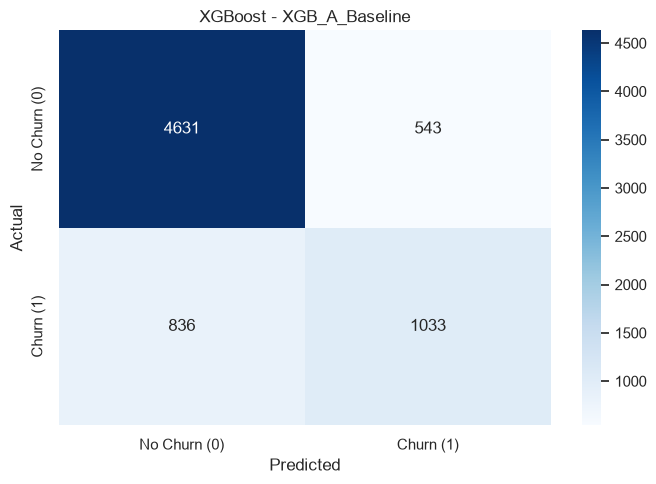

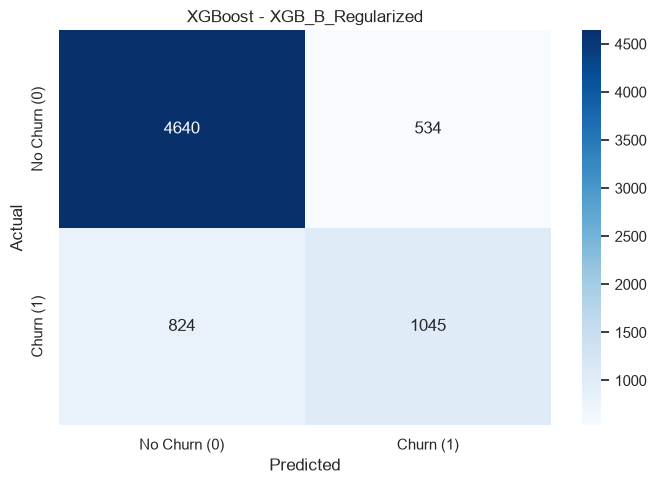

In [31]:
# Matrizes de confusão

for configuration_name, cm in xgb_confusion_matrices.items():

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn (0)", "Churn (1)"],
        yticklabels=["No Churn (0)", "Churn (1)"]
    )

    plt.title(f"XGBoost - {configuration_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.show()


In [32]:
# Salvando os resultado

# Salvando resultado por fold
xgb_results_df.to_csv(
    results_dir / "xgboost_resultados_por_fold.csv",
    index=False
)

# Salvando sumário dos resultados
xgb_summary.to_csv(
    results_dir / "xgboost_resumo.csv"
)

# Salvando resultado de todos fold
xgb_oof_df.to_csv(
    results_dir / "xgboost_resultados_oof.csv"
)

# Salvando matriz de confusão
for configuration_name, cm in xgb_confusion_matrices.items():

    cm_df = pd.DataFrame(
        cm,
        index=["Actual No Churn", "Actual Churn"],
        columns=["Predicted No Churn", "Predicted Churn"]
    )

    cm_df.to_csv(
        confusion_dir / f"{configuration_name}.csv"
    )


print("Resultados de XGBoost salvos")


Resultados de XGBoost salvos
